# Pertemuan 7 — Praktikum 5: Benchmark Recall dan Query Time

Perbandingan ANN biasanya disajikan dalam bentuk grafik dengan *recall* pada sumbu X dan *queries per second* atau waktu query pada sumbu Y. Recall menunjukkan seberapa banyak tetangga yang ditemukan sama dengan hasil pencarian exact. Nilai recall mendekati 1 berarti hasil pencarian hampir sama persis dengan pencarian exact, sedangkan recall yang rendah berarti banyak tetangga yang ditemukan berbeda. Sumbu Y menunjukkan kecepatan algoritma dalam menjawab query.

Posisi kanan atas pada grafik menunjukkan kondisi ideal, yaitu hasil yang akurat sekaligus cepat. Setiap algoritma ANN sebenarnya melakukan kompromi antara akurasi dan kecepatan, sehingga menaikkan akurasi biasanya menurunkan kecepatan.

Percobaan ini memakai 100.000 vektor berdimensi 128 dengan 1.000 query. Hasil pencarian exact dari `IndexFlatL2` dipakai sebagai acuan kebenaran (*ground truth*). Setiap pustaka dibangun satu kali, lalu parameter pencariannya divariasikan untuk melihat pergeseran titik pada grafik. Pendekatan ini setara dengan modul, karena parameter yang divariasikan hanya berpengaruh pada tahap pencarian dan tidak mengubah index.

Sumber: [Praktikum 5](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js06-ann-approximate-nearest-neighbors/praktikum-5).

In [1]:
%matplotlib inline

import time

import faiss
import hnswlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from annoy import AnnoyIndex

## 1. Menyiapkan dataset dan ground truth

Dataset terdiri atas 100.000 vektor database dan 1.000 vektor query. Ground truth dihitung dengan `IndexFlatL2` yang bersifat exact.

In [2]:
# -------------------------------
# Dataset random
# -------------------------------
d = 128        # dimensi
nb = 100000    # jumlah database vector
nq = 1000      # jumlah query

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

# -------------------------------
# Ground truth dengan FAISS brute force
# -------------------------------
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

## 2. Fungsi recall

Recall dihitung dari banyaknya tetangga yang sama antara hasil pencarian approximate dan hasil pencarian exact, dibagi dengan jumlah tetangga yang diminta untuk seluruh query.

In [3]:
# -------------------------------
# Fungsi recall
# -------------------------------
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

## 3. Pembangunan index

Ketiga index dibangun satu kali. Pencarian pada tahap berikutnya memakai index yang sama dengan parameter pencarian yang berbeda.

In [4]:
# -------------------------------
# Bangun index Annoy
# -------------------------------
ann_index = AnnoyIndex(d, 'euclidean')
for i, v in enumerate(xb):
    ann_index.add_item(i, v)
ann_index.build(10)

# -------------------------------
# Bangun index FAISS IVF
# -------------------------------
quantizer = faiss.IndexFlatL2(d)
faiss_index = faiss.IndexIVFFlat(quantizer, d, 100, faiss.METRIC_L2)
faiss_index.train(xb)
faiss_index.add(xb)

# -------------------------------
# Bangun index HNSW
# -------------------------------
hnsw_index = hnswlib.Index(space='l2', dim=d)
hnsw_index.init_index(max_elements=nb, ef_construction=200, M=16)
hnsw_index.add_items(xb)

## 4. Pengukuran recall dan waktu query

Setiap pustaka dijalankan dengan beberapa nilai parameter pencarian. Pada Annoy divariasikan `search_k`, pada FAISS divariasikan `nprobe`, dan pada HNSW divariasikan `ef`. Waktu yang dicatat adalah waktu rata-rata per query dalam milidetik.

In [5]:
def jalankan_annoy(search_k, k=10):
    start = time.perf_counter()
    I = [ann_index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.perf_counter() - start) * 1000 / len(xq)  # ms/query
    return recall_at_k(I, gt_idx, k), elapsed


def jalankan_faiss(nprobe, k=10):
    faiss_index.nprobe = nprobe
    start = time.perf_counter()
    _, I = faiss_index.search(xq, k)
    elapsed = (time.perf_counter() - start) * 1000 / len(xq)
    return recall_at_k(I, gt_idx, k), elapsed


def jalankan_hnsw(ef, k=10):
    hnsw_index.set_ef(ef)
    start = time.perf_counter()
    I, _ = hnsw_index.knn_query(xq, k)
    elapsed = (time.perf_counter() - start) * 1000 / len(xq)
    return recall_at_k(I, gt_idx, k), elapsed


results = {"Annoy": [], "Faiss": [], "HNSW": []}
parameter = {"Annoy": [200, 500, 1000, 2000], "Faiss": [1, 5, 10, 20], "HNSW": [50, 100, 200, 400]}

for sk in parameter["Annoy"]:
    results["Annoy"].append(jalankan_annoy(sk))

for npb in parameter["Faiss"]:
    results["Faiss"].append(jalankan_faiss(npb))

for ef in parameter["HNSW"]:
    results["HNSW"].append(jalankan_hnsw(ef))

## 5. Tabel hasil benchmark

Hasil setiap kombinasi parameter dicatat dalam tabel agar hubungan antara recall, kecepatan, dan nilai parameter dapat dibaca.

In [6]:
baris = []
for nama in ("Annoy", "Faiss", "HNSW"):
    for nilai, (rec, t) in zip(parameter[nama], results[nama]):
        nama_param = {"Annoy": "search_k", "Faiss": "nprobe", "HNSW": "ef"}[nama]
        baris.append({
            "Library": nama,
            "Parameter": f"{nama_param}={nilai}",
            "Recall@10": round(rec, 4),
            "Query time (ms/query)": round(t, 4),
        })

tabel_benchmark = pd.DataFrame(baris)
display(tabel_benchmark)

,Library,Parameter,Recall@10,Query time (ms/query)
0,Annoy,search_k=200,0.0248,0.0714
1,Annoy,search_k=500,0.0486,0.1254
2,Annoy,search_k=1000,0.0808,0.2084
3,Annoy,search_k=2000,0.1287,0.3900
4,Faiss,nprobe=1,0.0558,0.0122
5,Faiss,nprobe=5,0.1981,0.0419
6,Faiss,nprobe=10,0.3239,0.0847
7,Faiss,nprobe=20,0.5031,0.1698
8,HNSW,ef=50,0.2985,0.0643
9,HNSW,ef=100,0.4384,0.1139


## 6. Visualisasi trade-off

Grafik menampilkan recall pada sumbu X dan waktu query pada sumbu Y dengan skala logaritmik. Sumbu Y dibalik agar posisi yang lebih tinggi menunjukkan waktu yang lebih singkat, sehingga titik yang lebih ke kanan atas menandakan kinerja yang lebih baik.

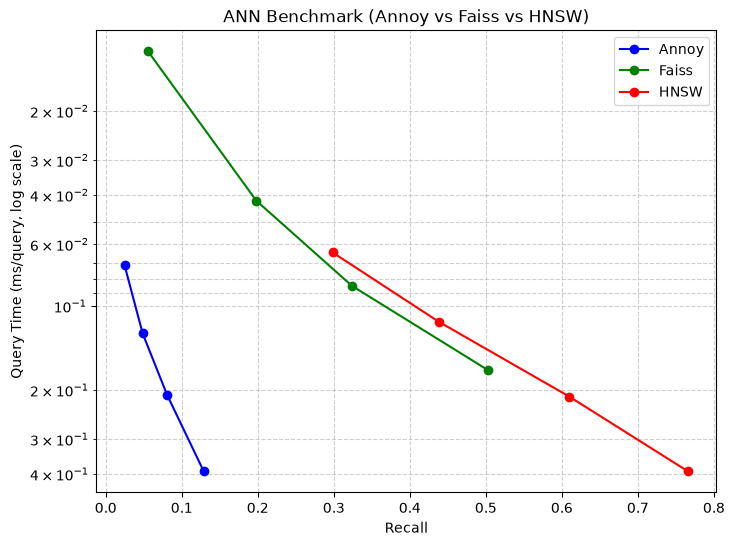

In [7]:
plt.figure(figsize=(8, 6))
for label, color in zip(results.keys(), ["blue", "green", "red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()  # invert Y, makin kanan makin turun
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

## Kesimpulan

Grafik memperlihatkan kompromi antara akurasi dan kecepatan pada setiap pustaka. Menaikkan `search_k` pada Annoy, `nprobe` pada FAISS, atau `ef` pada HNSW menaikkan recall, tetapi waktu query juga bertambah. Pada percobaan ini HNSW mencapai recall tinggi dengan waktu query terkecil, sehingga titiknya berada paling kanan atas. FAISS dengan `nprobe` kecil memiliki waktu query yang sangat singkat tetapi recallnya rendah, sedangkan Annoy menghasilkan recall yang lebih rendah lagi dengan waktu query yang justru lebih lama daripada FAISS pada tingkat recall yang sama. Pada data acak berdimensi 128 ini, Annoy memerlukan nilai `search_k` yang jauh lebih besar agar recallnya menyaingi kedua metode lainnya. Dengan demikian, pemilihan algoritma dan parameter pencarian bergantung pada kebutuhan aplikasi, apakah lebih menekankan akurasi atau kecepatan.